# 모델과 도구 실습: 주문 취소 문의를 도구 둘로 처리하고 사람 확인 값 바꾸기

**이 노트북에서 할 일**

1. 06절 읽기 도구와, 02절 입력 검사를 붙인 쓰기 도구를 부품으로 만듭니다.
2. 사람 확인 값으로 목록을 고르는 조립 함수로 주문 취소 문의 하나를 처리합니다.
3. 사람 확인 값 하나만 바꿔 다시 실행하고, 두 실행을 한 표로 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 모두 4~5번입니다.
교재 출력에서는 실행 1이 2번, 실행 2가 3번으로 모두 5번이었습니다.
바퀴 한도가 5라서, 실행 한 번의 요청은 5번을 넘지 않습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

읽기 도구는 실습 폴더의 주문 CSV를 읽기만 합니다.
쓰기 도구는 06절처럼 이 절에서 만든 흉내라 아무 파일도 바꾸지 않습니다.
앞 절 함수와 Ch 6 06절 함수는 도구 파일 `order_tools.py`에서 가져옵니다.
걸린 시간은 재지 않습니다. 교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pandas 3.0.5, pydantic 2.12.5, python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~06절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위에 초록 상자 주문 문의 하나 O102가 결제 대기 중이면 취소 까닭은 잘못 주문함, 초록 상자 바꾸는 값 하나 사람 확인 값 person_confirmed, 회색 상자 부품 둘 읽기 도구 get_order_by_id 쓰기 도구 request_cancel 입력 형식 CancelForm이 나란히 있고, 셋이 가운데 파란 상자 조립 함수 handle_inquiry 06절 pick_tools로 목록 고르기 bind_tools 도구 찾기 표로 모인 뒤 파란 상자 05절 ask_until_answer 도구 실행과 다시 묻기로 이어지며, 그 아래 왼쪽 보라 상자 gpt-5.4-mini 도구 호출 요청 또는 최종 답과는 메시지 목록과 응답 화살표가 오가고, 오른쪽 아래 노란 상자 실행 요약 명세 요청한 도구 결과 상태 요청 수로 끝나는 그림](attachment:07-1-취소-문의-조립도.png)

위에서 아래로 읽습니다. 맨 위 초록 상자 둘은 손으로 정한 문의와 바꾸는 값이고, 오른쪽 회색 상자는 부품 둘입니다. 가운데 파란 조립 함수가 사람 확인 값으로 알려 줄 목록을 고릅니다. 그 아래 파란 반복 상자는 왼쪽 아래 보라 모델과 메시지 목록과 응답을 주고받습니다. 오른쪽 아래 노란 상자는 실행마다 출력하는 실행 요약입니다.
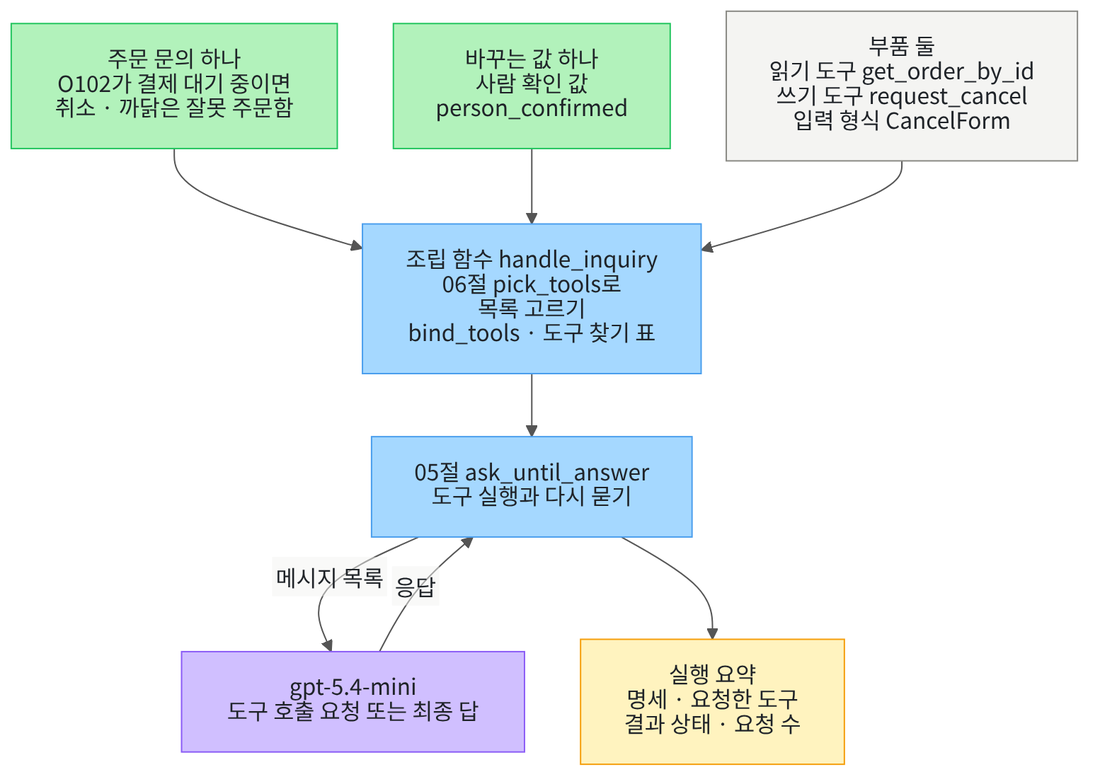

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~06절에서 쓴 이름과 문법만 쓰고, 따로 내는 과제는 없습니다.
첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "pandas==3.0.5" "pydantic==2.12.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("pandas:", version("pandas"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
pandas: 3.0.5
pydantic: 2.12.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `pandas: 3.0.5`·`pydantic: 2.12.5`·`python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 실습에서 쓸 이름을 가져옵니다.
도구 파일에서는 03~06절 함수 여덟과 Ch 6 06절 함수 `estimate_cost`를 가져옵니다.

In [2]:
# 모델·도구·양식 클래스·메시지를 만드는 이름과, 도구 파일에서 앞 절 함수 아홉을 가져옵니다
import os
from typing import Literal

from langchain.chat_models import init_chat_model
from langchain.tools import ToolException, tool
from langchain_core.messages import HumanMessage
from pydantic import BaseModel, Field, ValidationError

from order_tools import ask_until_answer, estimate_cost, find_order, make_tools_table, pick_tools, show_messages, spec_names, sum_usage, tool_call_names

print("가져온 이름:", "os", "Literal", "init_chat_model", "ToolException", "tool", "HumanMessage")
print("가져온 이름:", "BaseModel", "Field", "ValidationError")

가져온 이름: os Literal init_chat_model ToolException tool HumanMessage
가져온 이름: BaseModel Field ValidationError


**결과 읽기** — 출력 두 줄에 셀 위쪽에서 가져온 이름 아홉이 보입니다.
도구 파일에서 가져온 함수 아홉은 셀의 `from order_tools import …` 줄에 적혀 있습니다.
양식 클래스를 만드는 `BaseModel`·`Field`와 오류 이름 `ValidationError`는 02절에서 쓴 이름입니다.
표시 `Literal`도 02절처럼 칸에 적을 수 있는 값을 몇 개로 정할 때 씁니다.

다음 셀은 01~06절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
읽기 도구의 몸통이 이 CSV 파일을 읽습니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.

## 2. 키와 모델 준비

모델은 04~06절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [4]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 고르는 도구가 매번 같다고 보장하지는 않습니다.

In [5]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 상황과 대상 주문

손님의 주문 문의를 받는 창구 하나를 만든다고 해 봅니다.
창구는 주문을 찾는 읽기 도구와, 취소 요청을 등록하는 쓰기 도구를 씁니다.
쓰기 도구는 06절처럼 사람이 확인한 뒤에만 모델에게 알려 줍니다.

다음 셀은 이 실습의 새 주문 문의를 적습니다.
이 절에서 실행 전에 정한 글이고, 실제 손님이 보낸 글이 아닙니다.

In [6]:
# 이 실습의 새 주문 문의를 적습니다(이 절에서 실행 전에 정한 글이고, 실제 손님이 보낸 글이 아닙니다)
inquiry = "O102 주문이 아직 결제 대기 중이면 취소해 주세요. 다른 상품을 잘못 주문했어요."
print("주문 문의:", inquiry)
print("출처:", "이 절에서 실행 전에 적은 글")

주문 문의: O102 주문이 아직 결제 대기 중이면 취소해 주세요. 다른 상품을 잘못 주문했어요.
출처: 이 절에서 실행 전에 적은 글


**결과 읽기** — 출력 줄 `주문 문의:` 뒤 두 문장이 창구에 넣을 문의입니다.
출력 줄 `출처: 이 절에서 실행 전에 적은 글`처럼 문의 글은 실행 전에 적었습니다.
문의에는 조건이 있어, 주문이 결제 대기 중일 때만 취소해 달라고 합니다.
까닭은 다른 상품을 잘못 주문했다는 것입니다.

다음 셀은 문의에 적힌 주문 O102를 03절 몸통 함수 `find_order`로 CSV에서 찾습니다.
모델 요청은 없습니다.

In [7]:
# 문의에 적힌 주문 O102를 03절 몸통 함수로 CSV에서 찾아 봅니다(모델 요청 없음)
target_order = find_order(csv_path, "O102")
print("문의 대상 주문:", target_order)
print("주문 상태:", target_order["status"])

문의 대상 주문: {'order_id': 'O102', 'customer_id': 'C002', 'status': 'pending', 'amount': 18000}
주문 상태: pending


**결과 읽기** — 라벨 `문의 대상 주문:` 뒤 딕셔너리는 주문 O102 한 줄이고, 금액은 `18000`입니다.
출력 줄 `주문 상태: pending`처럼 O102는 결제 대기 중입니다.
02절에서 본 것처럼 실습 CSV에서 결제 대기 중인 주문은 O102 하나뿐이라, 이 번호를 문의에 적었습니다.

## 4. 부품 하나 · 읽기 도구

첫 부품은 06절의 읽기 도구입니다.
다음 셀은 06절 노트북 3절 셀을 그대로 다시 적습니다.
찾지 못하면 None 대신 도구 오류(`ToolException`)를 내는 도구입니다.

In [8]:
# 주문 한 건을 찾는 읽기 도구를 만들고, 없는 주문이면 도구 오류를 냅니다
@tool
def get_order_by_id(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 오류를 냅니다."""
    order = find_order(csv_path, order_id)
    # 찾지 못하면 None 대신 도구 오류를 내서, 무엇이 잘못됐는지 글로 알립니다
    if order is None:
        raise ToolException("주문 번호 " + order_id + "에 맞는 주문이 없습니다. 주문 번호를 다시 확인해 주세요.")
    return order

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름과 설명, 몸통이 06절 노트북 3절 셀과 글자까지 같습니다.
몸통은 도구 파일의 `find_order`로 주문을 찾고, 없으면 `raise` 줄로 도구 오류를 냅니다.

다음 셀은 06절 After처럼 오류 담기 설정을 켜고, 읽기 도구 목록에 담습니다.
이번 문의는 CSV에 있는 주문이라, 도구 오류는 나지 않을 것으로 예상합니다.

In [9]:
# 06절 After처럼 읽기 도구의 오류 담기 설정을 켜고, 읽기 도구 목록에 담습니다
get_order_by_id.handle_tool_error = True
read_tools = [get_order_by_id]
print("읽기 도구:", read_tools[0].name)
print("오류 담기 설정(handle_tool_error):", get_order_by_id.handle_tool_error)

읽기 도구: get_order_by_id
오류 담기 설정(handle_tool_error): True


**결과 읽기** — 출력 줄 `읽기 도구: get_order_by_id`와 `오류 담기 설정(handle_tool_error): True`가 보입니다.
모델이 없는 주문 번호를 적어 보내면 읽기 도구가 도구 오류를 냅니다.
이 설정이 켜져 있어, 그 오류는 흐름을 멈추지 않고 결과 상태 `error`인 도구 메시지가 됩니다.
이 설정은 읽기 도구에만 켰고, 쓰기 도구의 입력 검사 오류는 받지 않습니다.
그 모습은 06절 7절에서 보았고, 이 실습에서는 다시 보지 않습니다.

## 5. 부품 둘 · 취소 까닭을 검사하는 쓰기 도구

둘째 부품은 06절의 쓰기 도구에 02절 입력 검사를 붙인 것입니다.
취소 요청에는 주문 번호와 함께 취소 까닭을 적게 합니다.
까닭은 정해 둔 셋 가운데 하나만 받고, 다른 글은 몸통이 실행되기 전에 막습니다.

다음 셀은 02절처럼 양식 클래스로 쓰기 도구의 입력 형식을 정합니다.

In [10]:
# 쓰기 도구의 입력 형식: 주문 번호 칸과, 정해 둔 셋 가운데 하나만 받는 취소 까닭 칸을 정합니다
class CancelForm(BaseModel):
    # 주문 번호 칸은 글이고, 칸 설명은 도구 명세에 그대로 실립니다
    order_id: str = Field(description="취소할 주문 번호")
    # 취소 까닭 칸에는 괄호 안 세 글 가운데 하나만 적을 수 있습니다
    reason: Literal["changed_mind", "wrong_order", "late_delivery"] = Field(description="취소 까닭")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
양식 클래스 `CancelForm`의 칸은 주문 번호 `order_id`와 취소 까닭 `reason` 둘입니다.
칸 `reason`에는 `changed_mind`·`wrong_order`·`late_delivery` 세 글 가운데 하나만 적을 수 있습니다.
세 글은 마음이 바뀜, 잘못 주문함, 배송이 늦음이라는 뜻이고, 이 절에서 정한 값입니다.

다음 셀은 이 양식 클래스를 입력 형식으로 붙여 쓰기 도구를 만듭니다.
02절처럼 `@tool` 줄 괄호 안에 입력 형식을 따로 주고, 매개변수 이름은 칸 이름과 같게 둡니다.
몸통은 06절처럼 흉내라, 받은 값만 적어 내놓고 아무 파일도 바꾸지 않습니다.

In [11]:
# 취소 까닭 양식을 입력 형식으로 붙여 쓰기 도구를 만듭니다(06절처럼 흉내라 아무 파일도 바꾸지 않습니다)
@tool(args_schema=CancelForm)
def request_cancel(order_id, reason):
    """주문 번호와 취소 까닭으로 주문 취소 요청을 등록합니다. 손님이 주문을 취소해 달라고 할 때 씁니다. 인자 reason은 정해 둔 취소 까닭 셋 가운데 하나입니다. 등록한 주문 번호와 까닭을 딕셔너리로 내놓습니다."""
    # 몸통이 실행되었는지 보이려고 받은 값을 먼저 출력합니다(02절과 같은 방법)
    print("쓰기 도구 몸통 실행 | 주문 번호:", order_id, "| 까닭:", reason)
    # 실제 서비스라면 여기서 주문 상태가 바뀝니다. 이 절에서는 받은 값만 적어 내놓습니다
    return {"order_id": order_id, "reason": reason, "cancel_requested": True}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
쓰기 도구의 공개 이름은 `request_cancel`이고, 하는 일을 뜻하는 동사 request를 앞에 두었습니다.
설명은 03절 자세한 판처럼 하는 일·사용 조건·인자·내놓는 값의 네 문장입니다.
몸통 첫 줄은 02절처럼 받은 값을 출력해, 몸통이 실행되었는지 보이게 합니다.

다음 셀은 쓰기 도구를 쓰기 도구 목록에 담고, 입력 형식의 취소 까닭 칸을 봅니다.

In [12]:
# 쓰기 도구를 쓰기 도구 목록에 담고, 입력 형식의 취소 까닭 칸을 봅니다(모델 요청 없음)
write_tools = [request_cancel]
print("쓰기 도구:", write_tools[0].name)
print("취소 까닭 칸:", request_cancel.args["reason"])

쓰기 도구: request_cancel
취소 까닭 칸: {'description': '취소 까닭', 'enum': ['changed_mind', 'wrong_order', 'late_delivery'], 'title': 'Reason', 'type': 'string'}


**결과 읽기** — 출력 줄 `쓰기 도구: request_cancel`이 보입니다.
라벨 `취소 까닭 칸:` 뒤 딕셔너리의 칸 `enum`에 세 글이 들어 있습니다.
02절 4절에서 본 것처럼, 이 칸은 도구 명세에도 실려 모델이 고를 수 있는 값이 됩니다.

다음 셀은 정해 둔 셋에 없는 까닭 `too_expensive`를 넣어 봅니다.
이 값은 이 절에서 정한 값이고, 모델 요청은 없습니다.
실행 전에 예상해 봅니다.
02절 7절처럼 입력 검사에 걸려, 몸통이 실행되기 전에 값 검사 오류가 날 것입니다.

In [13]:
# 정해 둔 셋에 없는 까닭 too_expensive를 넣어 봅니다(모델 요청 없음, 이 셀만 그 오류를 받아 출력합니다)
try:
    request_cancel.invoke({"order_id": "O102", "reason": "too_expensive"})
except ValidationError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:")
    print(error)

받은 오류: ValidationError
오류 글:
1 validation error for CancelForm
reason
  Input should be 'changed_mind', 'wrong_order' or 'late_delivery' [type=literal_error, input_value='too_expensive', input_type=str]
    For further information visit https://errors.pydantic.dev/2.12/v/literal_error


**결과 읽기** — 출력 줄 `받은 오류: ValidationError`처럼 값 검사 오류가 셀까지 올라왔습니다.
라벨 줄 `오류 글:` 아래 첫 줄은 `1 validation error for CancelForm`이고, 걸린 칸은 `reason`입니다.
출력에 「쓰기 도구 몸통 실행」으로 시작하는 줄이 없어, 몸통은 실행되지 않았습니다.
오류를 받지 않는 실제 프로그램이라면 여기서 멈춥니다.

## 6. 조립 함수와 기록 장치

부품이 모였으니, 문의 하나를 처리하는 조립 함수를 만듭니다.
조립 함수는 06절 함수 `pick_tools`로 알려 줄 목록을 고릅니다.
그다음 05절 함수 `ask_until_answer`로 도구 호출 요청이 없는 응답까지 처리합니다.
함수 안 주석에 어느 절에서 배운 일인지 적었습니다.

In [14]:
# 조립 함수: 06절 pick_tools로 알려 줄 목록을 고르고, 05절 ask_until_answer로 문의를 끝까지 처리합니다
def handle_inquiry(model, read_tools, write_tools, person_confirmed, question, turn_limit):
    # 06절: 사람 확인 값으로 목록을 고르고, 같은 목록으로 명세와 도구 찾기 표를 만듭니다
    tools = pick_tools(read_tools, write_tools, person_confirmed)
    bound_model = model.bind_tools(tools, parallel_tool_calls=False)
    tools_by_name = make_tools_table(tools)
    # 05절: 질문 하나로 새 메시지 목록을 만들어, 도구 호출 요청이 없는 응답까지 처리합니다
    messages = [HumanMessage(content=question)]
    messages = ask_until_answer(bound_model, messages, tools_by_name, turn_limit)
    return {"사람 확인": person_confirmed, "명세": spec_names(bound_model), "메시지": messages}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `handle_inquiry`는 모델, 두 도구 목록, 사람 확인 값, 문의 글, 바퀴 한도를 받습니다.
알려 준 목록으로 명세와 도구 찾기 표를 함께 만들어, 알려 주지 않은 도구는 실행할 수 없게 합니다.
흐름 결과는 사람 확인 값, 명세 이름, 메시지 목록을 담은 딕셔너리입니다.

다음 셀은 이 실습의 기록 장치입니다.
흐름 결과 하나에서 볼 값을 실행 요약 딕셔너리 하나로 모읍니다.

In [15]:
# 기록 장치: 흐름 결과 하나에서 사람 확인 값·명세·요청한 도구·결과 상태·요청 수를 실행 요약으로 모읍니다
def summarize_run(result):
    summary = {"사람 확인": result["사람 확인"], "명세": result["명세"], "요청한 도구": [], "결과 상태": []}
    for message in result["메시지"]:
        # 응답이면 04절 함수로 도구 호출 요청 이름을, 도구 메시지면 결과 상태를 차례대로 모읍니다
        if type(message).__name__ == "AIMessage":
            summary["요청한 도구"] = summary["요청한 도구"] + tool_call_names(message)
        if type(message).__name__ == "ToolMessage":
            summary["결과 상태"].append(message.status)
    # 요청 수는 05절 함수 sum_usage로 센 모델 응답 수입니다
    summary["요청 수"] = sum_usage(result["메시지"])["requests"]
    return summary

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `summarize_run`은 응답에서 04절 함수로 도구 호출 요청 이름을 모읍니다.
도구 메시지에서는 결과 상태를 모읍니다.
05절에서 본 것처럼 요청마다 도구 메시지가 하나씩 생겨, 결과 상태 수는 요청한 도구 수와 같습니다.
요청 수는 05절 함수 `sum_usage`로 센 모델 응답 수입니다.

다음 셀은 실행 요약 여러 개를 받아 실행마다 한 줄로 출력합니다.

In [16]:
# 기록 장치: 실행 요약을 실행마다 한 줄로 출력합니다
def print_summaries(summaries):
    print("사람 확인 | 명세 | 요청한 도구 | 결과 상태 | 요청 수")
    for summary in summaries:
        print(summary["사람 확인"], "|", summary["명세"], "|", summary["요청한 도구"], "|", summary["결과 상태"], "|", summary["요청 수"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_summaries`는 라벨 줄을 먼저 출력하고, 실행 요약 하나마다 한 줄씩 출력합니다.
칸은 06절 함수 `show_messages`의 출력처럼 세로 막대로 나눕니다.

## 7. 실행 1 · 사람 확인 전

실행 1은 사람 확인 전이라 `person_confirmed`를 `False`로 둡니다.
바퀴 한도는 06절과 같은 5입니다.

실행 전에 예상해 봅니다.
명세에는 읽기 도구 하나만 실리고, 모델은 먼저 O102의 상태를 읽을 것입니다.
쓰기 도구를 모르니 취소는 요청하지 못하고, 글로 답할 것입니다.
그러면 읽기 도구를 요청한 응답과 최종 답, 모두 두 번 요청할 것입니다.

In [17]:
# 실행 1: 사람 확인 전(False)으로 문의를 끝까지 처리합니다(모델 요청 2번 안팎)
turn_limit = 5
person_confirmed = False
result_one = handle_inquiry(model, read_tools, write_tools, person_confirmed, inquiry, turn_limit)
print("실어 보낸 도구 이름:", result_one["명세"])
show_messages(result_one["메시지"])
print("답 글:")
print(result_one["메시지"][-1].content)

실어 보낸 도구 이름: ['get_order_by_id']
HumanMessage
AIMessage | 도구 호출 요청: ['get_order_by_id']
ToolMessage | 결과 상태: success | 내용: {"order_id": "O102", "customer_id": "C002", "status": "pending", "amount": 18000}
AIMessage | 도구 호출 요청: []
답 글:
O102 주문은 현재 **결제 대기 중(pending)** 이라서 취소 가능합니다.  
다른 상품을 잘못 주문하셨다면, 이 주문은 **취소 처리**해 드릴 수 있습니다.

다만 현재 이 대화에서는 실제 취소 실행 기능이 없어, 제가 바로 상태를 변경하진 못합니다.  
원하시면 제가 **취소 요청 문구**를 바로 정리해 드릴게요.


**결과 읽기** — 출력 줄 `실어 보낸 도구 이름: ['get_order_by_id']`로 명세에는 읽기 도구 하나만 실렸습니다.
응답 줄은 `AIMessage | 도구 호출 요청: ['get_order_by_id']`와 `AIMessage | 도구 호출 요청: []`입니다.
도구 메시지 줄은 `결과 상태: success`이고, 내용에서 O102의 상태 `pending`을 읽었습니다.
출력에 「쓰기 도구 몸통 실행」으로 시작하는 줄이 없습니다.

라벨 줄 `답 글:` 아래가 모델이 적은 최종 답이고, 문장은 실행마다 달라질 수 있습니다.
이번 실행에서는 답 글이 O102가 결제 대기 중이라 취소할 수 있다고 적었습니다.
다만 이 대화에는 실제 취소 기능이 없어, 상태를 바꾸지 못한다고도 적었습니다.
새 커널로 한 번 더 실행했을 때는 「취소 처리해 드릴게요」처럼 적은 답 글도 나왔습니다.
답 글이 무엇이라고 적든, 이 흐름에 쓰기 도구 요청은 없었습니다.

다음 셀은 실행 1의 값을 실행 요약으로 모아 한 줄로 봅니다.

In [18]:
# 실행 1의 요약을 한 줄로 보고, 쓰기 도구 요청이 있었는지 봅니다(모델 요청 없음)
summary_one = summarize_run(result_one)
print_summaries([summary_one])
print("쓰기 도구 요청이 있었는가:", "request_cancel" in summary_one["요청한 도구"])

사람 확인 | 명세 | 요청한 도구 | 결과 상태 | 요청 수
False | ['get_order_by_id'] | ['get_order_by_id'] | ['success'] | 2
쓰기 도구 요청이 있었는가: False


**결과 읽기** — 라벨 줄 `사람 확인 | 명세 | 요청한 도구 | 결과 상태 | 요청 수` 아래 한 줄이 실행 1의 요약입니다.
출력 줄 `False | ['get_order_by_id'] | ['get_order_by_id'] | ['success'] | 2`를 봅니다.
출력 줄 `쓰기 도구 요청이 있었는가: False`로 쓰기 도구 요청은 없었습니다.
요청 수 2는 읽기 도구를 요청한 응답과 최종 답을 더한 수이고, 예상과 맞았습니다.

## 8. 실행 2 · 사람 확인 뒤

바꿀 값은 `person_confirmed` 하나이고, `False`를 `True`로 바꿉니다.
사람이 이 문의의 취소를 확인했다고 노트북이 기록한 경우입니다.
문의 글과 두 도구, 바퀴 한도, 조립 함수는 실행 1과 같습니다.

실행 전에 예상해 봅니다.
명세에 쓰기 도구가 더해지고, 모델은 먼저 O102의 상태를 읽을 것입니다.
결제 대기 중이니 쓰기 도구를 요청하고, 프로그램이 그 도구를 실행할 것입니다.
그러면 읽기, 쓰기, 최종 답으로 세 번 요청할 것입니다.

In [19]:
# 실행 2: 바꿀 값은 person_confirmed 하나이고, True로 바꿔 같은 문의를 처리합니다(모델 요청 3번 안팎)
person_confirmed = True
result_two = handle_inquiry(model, read_tools, write_tools, person_confirmed, inquiry, turn_limit)
print("실어 보낸 도구 이름:", result_two["명세"])
show_messages(result_two["메시지"])
print("답 글:")
print(result_two["메시지"][-1].content)

쓰기 도구 몸통 실행 | 주문 번호: O102 | 까닭: wrong_order


실어 보낸 도구 이름: ['get_order_by_id', 'request_cancel']
HumanMessage
AIMessage | 도구 호출 요청: ['get_order_by_id']
ToolMessage | 결과 상태: success | 내용: {"order_id": "O102", "customer_id": "C002", "status": "pending", "amount": 18000}
AIMessage | 도구 호출 요청: ['request_cancel']
ToolMessage | 결과 상태: success | 내용: {"order_id": "O102", "reason": "wrong_order", "cancel_requested": true}
AIMessage | 도구 호출 요청: []
답 글:
O102 주문은 결제 대기 중이어서 취소 요청을 등록했습니다.  
취소 사유: 잘못 주문함


**결과 읽기** — 출력 줄 `실어 보낸 도구 이름: ['get_order_by_id', 'request_cancel']`로 명세가 둘이 되었습니다.
출력 줄 `쓰기 도구 몸통 실행 | 주문 번호: O102 | 까닭: wrong_order`는 쓰기 도구 몸통이 찍은 줄입니다.
응답 줄의 도구 호출 요청은 차례로 `['get_order_by_id']`, `['request_cancel']`, `[]`입니다.
도구 메시지 둘은 모두 `결과 상태: success`이고, 둘째 내용에 `"cancel_requested": true`가 있습니다.
모델이 적은 취소 까닭이 입력 검사를 지나, 몸통이 실행되었습니다.

라벨 줄 `답 글:` 아래 최종 답 문장은 실행마다 달라질 수 있습니다.
이번 실행에서는 답 글이 취소 요청을 등록했다고 적었습니다.
노트북 밖에서 다섯 번 보냈을 때도 세 응답의 도구 호출 요청 차례와 까닭 `wrong_order`는 다섯 번 모두 같았습니다.

다음 셀은 쓰기 도구가 흉내였는지, 주문 CSV에서 O102의 상태를 다시 읽어 봅니다.

In [20]:
# 쓰기 도구가 흉내였는지, 주문 CSV에서 O102의 상태를 다시 읽어 봅니다(모델 요청 없음)
order_after = find_order(csv_path, "O102")
print("CSV의 O102 상태:", order_after["status"])
# CSV 파일에서 정해지는 값이라 assert로 확인할 수 있습니다
assert order_after["status"] == "pending", "쓰기 도구는 흉내라 CSV를 바꾸지 않아야 합니다"

CSV의 O102 상태: pending


**결과 읽기** — 출력 줄 `CSV의 O102 상태: pending`으로, 주문 CSV는 그대로입니다.
쓰기 도구가 흉내라 파일을 바꾸지 않았다는 것을 코드로 확인했습니다.
이 값은 CSV 파일에서 정해져서, 셀 끝의 `assert`로도 확인했습니다.
실제 쓰기 도구였다면, 사람 확인 뒤 이 자리에서 주문 상태가 바뀌었을 것입니다.

## 9. 두 실행 견주기

다음 셀은 두 실행의 요약을 한 표로 견주고, 쓰기 도구 요청이 있었는지 실행마다 봅니다.

In [21]:
# 두 실행의 요약을 한 표로 견주고, 쓰기 도구 요청이 있었는지 실행마다 봅니다(모델 요청 없음)
summary_two = summarize_run(result_two)
print_summaries([summary_one, summary_two])
print("쓰기 도구 요청 | 실행 1", "request_cancel" in summary_one["요청한 도구"], "| 실행 2", "request_cancel" in summary_two["요청한 도구"])

사람 확인 | 명세 | 요청한 도구 | 결과 상태 | 요청 수
False | ['get_order_by_id'] | ['get_order_by_id'] | ['success'] | 2
True | ['get_order_by_id', 'request_cancel'] | ['get_order_by_id', 'request_cancel'] | ['success', 'success'] | 3
쓰기 도구 요청 | 실행 1 False | 실행 2 True


**결과 읽기** — 라벨 줄 아래 두 줄을 견줍니다.
출력 줄 `False | ['get_order_by_id'] | ['get_order_by_id'] | ['success'] | 2`가 실행 1입니다.
출력 줄 `True | ['get_order_by_id', 'request_cancel'] | ['get_order_by_id', 'request_cancel'] | ['success', 'success'] | 3`이 실행 2입니다.
출력 줄 `쓰기 도구 요청 | 실행 1 False | 실행 2 True`로, 쓰기 도구는 실행 2에서만 요청되었습니다.
사람 확인 값 하나로 명세가 달라졌고, 명세에 있던 쓰기 도구만 흐름 안에서 실행되었습니다.

다음 셀은 두 실행의 첫 요청 입력 토큰을 견줍니다.
질문은 같고, 실어 보낸 명세만 다릅니다.

In [22]:
# 두 실행의 첫 요청 입력 토큰을 견줍니다: 질문은 같고, 실어 보낸 명세만 다릅니다(모델 요청 없음)
first_one = result_one["메시지"][1]
first_two = result_two["메시지"][1]
print("두 실행의 질문이 같은가:", result_one["메시지"][0].content == result_two["메시지"][0].content)
print("첫 요청 입력 토큰 | 실행 1", first_one.usage_metadata["input_tokens"], "| 실행 2", first_two.usage_metadata["input_tokens"])

두 실행의 질문이 같은가: True
첫 요청 입력 토큰 | 실행 1 203 | 실행 2 319


**결과 읽기** — 출력 줄 `두 실행의 질문이 같은가: True`로 두 실행의 첫 메시지는 같은 문의입니다.
출력 줄 `첫 요청 입력 토큰 | 실행 1 203 | 실행 2 319`를 봅니다.
쓰기 도구의 이름·설명·입력 형식이 더 실려, 실행 2의 첫 요청 입력 토큰이 더 많습니다.
명세는 요청마다 실리므로, 쓰기 도구를 알려 주면 흐름의 모든 요청에 이 몫이 붙습니다.

## 10. 요청 수와 예상 비용

다음 셀은 두 실행의 모델 응답을 모두 모아, 요청 수와 토큰을 셉니다.
05절 함수 `sum_usage`로 더하고, Ch 6 06절 요금표로 예상 비용을 셉니다.

In [23]:
# 두 실행의 모델 응답을 모두 모아 요청 수·토큰과 예상 비용을 셉니다(요청 없음)
all_messages = result_one["메시지"] + result_two["메시지"]
total_usage = sum_usage(all_messages)
pricing_date = "2026-09-17"
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
total_cost = estimate_cost(total_usage, input_rate, cached_input_rate, output_rate)
print("요금 확인 날짜:", pricing_date)
print("모두 합친 사용량:", total_usage)
print("예상 비용(달러):", round(total_cost, 6))

요금 확인 날짜: 2026-09-17
모두 합친 사용량: {'requests': 5, 'input_tokens': 1608, 'output_tokens': 194}
예상 비용(달러): 0.002079


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절 요금표를 확인한 날짜입니다.
라벨 `모두 합친 사용량:` 뒤 딕셔너리의 칸 `requests`가 두 실행의 모델 요청 수입니다.
예상 비용은 요금표로 어림한 값이고 청구 금액이 아닙니다.

이번 실행에서는 칸 `requests`가 5이고, 예상 비용은 0.002079달러였습니다.
새 커널로 한 번 더 실행했을 때는 출력 토큰 합이 154라, 예상 비용도 0.001899달러로 달랐습니다.
두 번의 답 글 길이가 달랐기 때문입니다.
요청 수 5와 입력 토큰 합 1608은 두 번 모두 같았습니다.

## 정리

1. 06절 읽기 도구와 02절 입력 검사를 붙인 쓰기 도구를 조립 함수 하나로 이어, 주문 취소 문의를 처리했습니다.
2. 사람 확인 전인 실행 1은 명세가 읽기 도구 하나였고, 쓰기 도구 요청 없이 두 번 요청으로 끝났습니다.
3. 사람 확인 값만 바꾼 실행 2는 쓰기 도구가 명세에 들어가 실행되었고, 흉내라 CSV는 그대로였습니다.

이 절로 Ch 19가 끝납니다.
Ch 20에서는 도구를 실행하고 다시 묻는 반복을, Ch 13의 상태 그래프로 조립합니다.